# 01. Strategic initiatives (Module 1: Corporate finance)

**Business question.** NovaFin has 180 strategic initiatives competing for limited capital. Which should it
**fund**, **review** or **reject**?

**Chain used in this notebook.**
Initiative data → ML model of `Historical_Success` (probability an initiative like this succeeds)
→ NPV and **expected NPV** → risk screen → Fund / Review / Reject → capital needed per business unit (feeds notebook 10).

**Brief tasks covered.**
1. Exploratory analysis: investment, ROI, risk, business units, growth vs ROI, investment vs success.
2. Predict `Historical_Success` with several models, compare them, explain the drivers (SHAP).
3. Approximate NPV, expected NPV, and a Fund / Review / Reject decision.

**Units.** The README says money is in INR lakh. Notebook 00 assumed the initiative file is in **₹ crore**
(an average project of ₹157 crore is realistic for a group-level initiative and makes the ₹1,000 crore budget a real
constraint). Every decision below uses *ratios* (NPV ÷ investment, probabilities), so the ranking is the same
under either unit. Only the absolute rupee totals would shrink by 100× if the file were in lakh.

In [1]:
# ---------------------------------------------------------------------------
# Setup: shared helpers (paths, assumptions, metrics, plot style) live in src/novafin.py
# ---------------------------------------------------------------------------
import sys; sys.path.insert(0, '../src')
from novafin import *
RES, FIG = use_module('01')                 # this module's output folders (results/ and figures/)

# scikit-learn pieces used in this notebook
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from scipy import stats

pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)

R = ASSUMPTIONS['DISCOUNT_RATE']          # 12% hurdle rate used to discount project cash flows
BUDGET = ASSUMPTIONS['TOTAL_CAPITAL_CR']  # ₹1,000 crore Board budget (upper bound on what can be funded)

init = load('initiatives')
print(init.shape, '| success rate:', round(init.Historical_Success.mean(), 3))
init.head()

NovaFin helpers loaded. Root: C:\Users\pravi\PG IITB\Machine Learning in Finance\capstone project solution\novafin_capstone
Outputs -> results/Module_01_Strategic_Initiatives/ and figures/Module_01_Strategic_Initiatives/


(180, 14) | success rate: 0.767


,Initiative_ID,Business_Unit,Initial_Investment,Revenue_Year1,Revenue_Year2,Revenue_Year3,Operating_Cost,Expected_ROI,Business_Growth,GDP_Growth,Interest_Rate,Competition_Index,Risk_Rating,Historical_Success
0,1001,SME Lending,131.13,35.21,42.86,45.76,41.72,5.48,5.65,5.56,7.82,50.22,Medium,1
1,1002,SME Lending,286.69,111.52,141.54,149.05,89.01,11.38,7.03,4.18,6.63,28.93,Medium,0
2,1003,Wealth,227.64,110.06,130.92,168.77,33.35,15.70,10.44,6.66,7.39,39.86,High,1
3,1004,Digital Banking,191.64,52.38,55.94,69.05,57.62,7.63,4.31,5.80,6.84,45.42,Medium,1
4,1005,Corporate Banking,72.13,25.30,30.84,35.10,15.47,7.82,8.68,6.21,7.12,65.21,Medium,0


## 1. Audit and explore (Task 1)
First a data-quality check (missing values, duplicates, impossible values), then the six views the brief asks for.

In [2]:
# Data-quality checks. Nothing is imputed: we only confirm the data are usable.
print('Missing values:', int(init.isna().sum().sum()), '| duplicate rows:', int(init.duplicated().sum()),
      '| duplicate IDs:', int(init.Initiative_ID.duplicated().sum()))
checks = {
    'Investment <= 0': (init.Initial_Investment <= 0).sum(),
    'Any revenue < 0': (init[['Revenue_Year1', 'Revenue_Year2', 'Revenue_Year3']] < 0).any(axis=1).sum(),
    'Operating cost < 0': (init.Operating_Cost < 0).sum(),
    'Competition index outside 0-100': (~init.Competition_Index.between(0, 100)).sum(),
}
print(pd.Series(checks, name='rows failing'))
init.describe().T[['mean', 'std', 'min', '50%', 'max']].round(2)

Missing values: 0 | duplicate rows: 0 | duplicate IDs: 0
Investment <= 0                    0
Any revenue < 0                    0
Operating cost < 0                 0
Competition index outside 0-100    0
Name: rows failing, dtype: int64


,mean,std,min,50%,max
Initiative_ID,1090.50,52.11,1001.00,1090.50,1180.00
Initial_Investment,157.47,79.39,31.49,155.32,296.46
Revenue_Year1,56.73,31.36,9.46,50.39,137.79
Revenue_Year2,67.78,37.28,11.40,59.76,167.86
Revenue_Year3,79.82,44.25,12.05,68.89,187.13
Operating_Cost,35.90,22.40,5.16,31.78,95.67
Expected_ROI,10.77,4.83,2.00,10.50,22.79
Business_Growth,8.23,2.97,-1.72,8.49,19.56
GDP_Growth,6.53,1.71,2.72,6.65,11.38
Interest_Rate,7.02,1.20,4.24,6.99,10.69


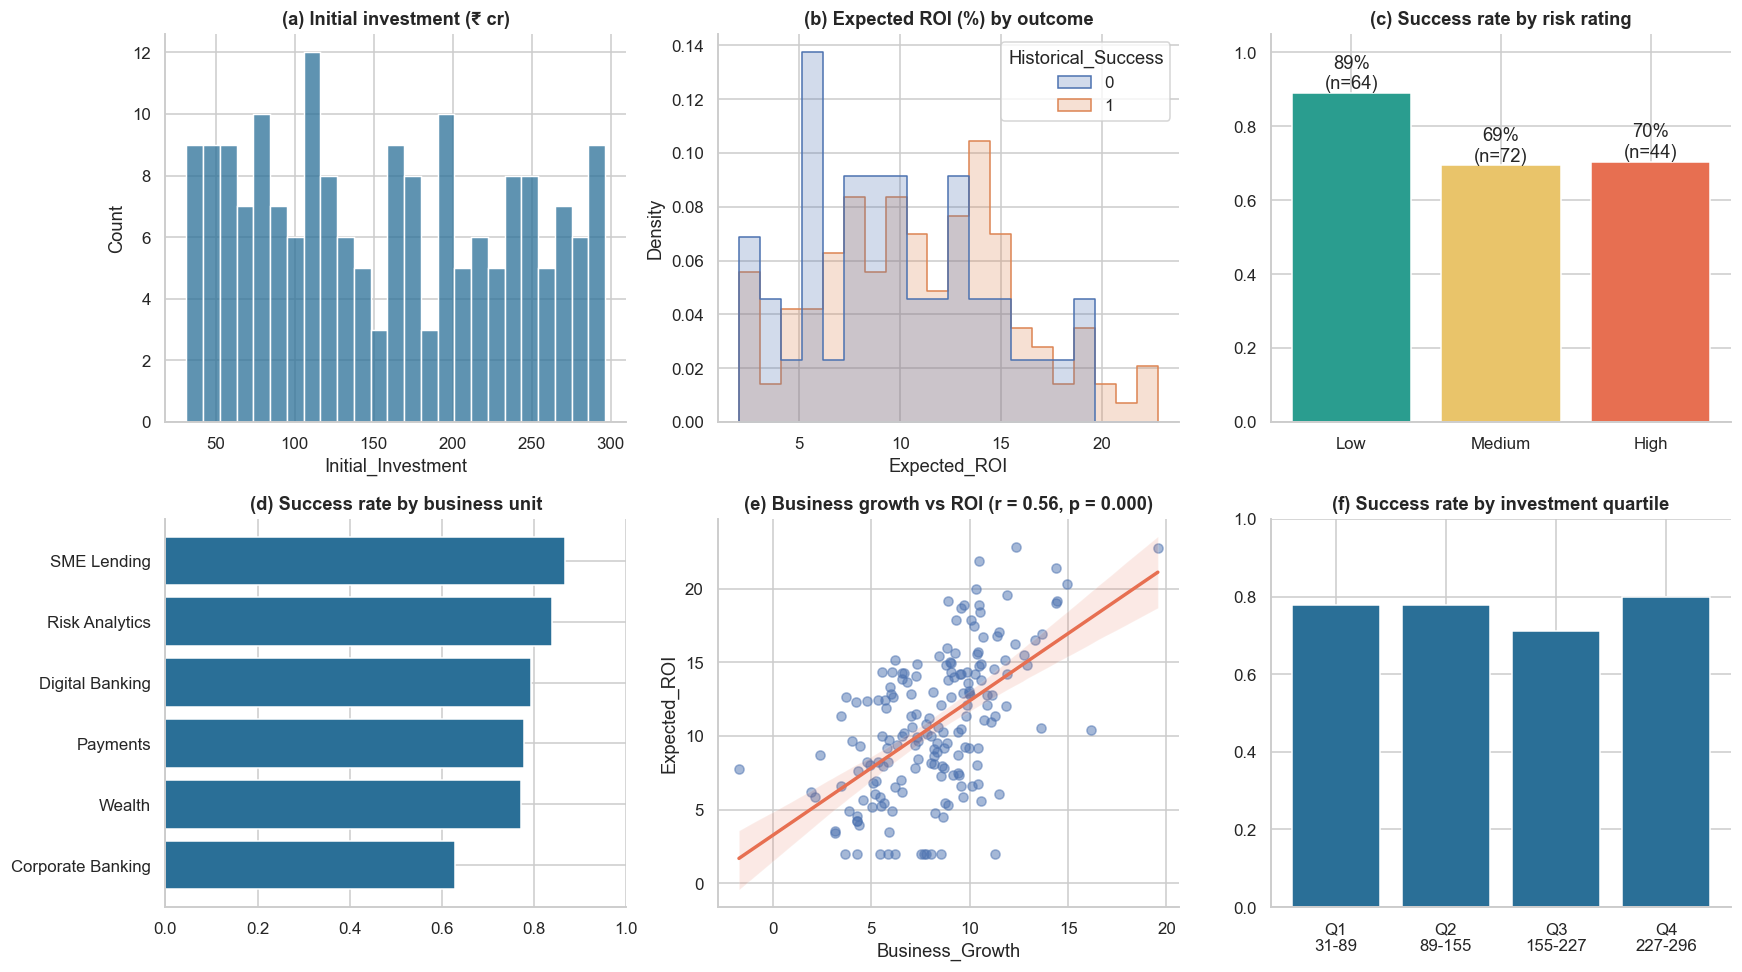

,n,success,roi,invest
Business_Unit,,,,
Corporate Banking,35,0.629,10.859,6232.09
Wealth,35,0.771,10.808,5861.30
Payments,36,0.778,10.571,5332.53
Digital Banking,34,0.794,12.224,4713.75
Risk Analytics,25,0.840,9.224,3977.15
SME Lending,15,0.867,10.194,2227.92


In [3]:
# Six EDA panels requested by the brief.
fig, ax = plt.subplots(2, 3, figsize=(16, 9))

# (a) Investment distribution
sns.histplot(init.Initial_Investment, bins=25, ax=ax[0, 0], color='#2a6f97')
ax[0, 0].set_title('(a) Initial investment (₹ cr)')

# (b) ROI distribution, split by success so we can see whether ROI separates the classes
sns.histplot(data=init, x='Expected_ROI', hue='Historical_Success', bins=20, ax=ax[0, 1], element='step', stat='density', common_norm=False)
ax[0, 1].set_title('(b) Expected ROI (%) by outcome')

# (c) Risk categories: count and success rate
rr = init.groupby('Risk_Rating').Historical_Success.agg(['size', 'mean']).loc[['Low', 'Medium', 'High']]
ax[0, 2].bar(rr.index, rr['mean'], color=['#2a9d8f', '#e9c46a', '#e76f51'])
for i, (n, m) in enumerate(zip(rr['size'], rr['mean'])):
    ax[0, 2].text(i, m + 0.01, f'{m:.0%}\n(n={n})', ha='center')
ax[0, 2].set_ylim(0, 1.05); ax[0, 2].set_title('(c) Success rate by risk rating')

# (d) Business-unit performance: success rate and average ROI
bu = init.groupby('Business_Unit').agg(n=('Historical_Success', 'size'), success=('Historical_Success', 'mean'),
                                       roi=('Expected_ROI', 'mean'), invest=('Initial_Investment', 'sum')).sort_values('success')
ax[1, 0].barh(bu.index, bu.success, color='#2a6f97'); ax[1, 0].set_xlim(0, 1)
ax[1, 0].set_title('(d) Success rate by business unit')

# (e) Growth vs ROI with a fitted line
sns.regplot(data=init, x='Business_Growth', y='Expected_ROI', ax=ax[1, 1], scatter_kws={'alpha': .5}, line_kws={'color': '#e76f51'})
r_g, p_g = stats.pearsonr(init.Business_Growth, init.Expected_ROI)
ax[1, 1].set_title(f'(e) Business growth vs ROI (r = {r_g:.2f}, p = {p_g:.3f})')

# (f) Investment vs success: success rate by investment quartile
q = pd.qcut(init.Initial_Investment, 4)
iq = init.groupby(q, observed=True).Historical_Success.mean()
ax[1, 2].bar(range(4), iq.values, color='#2a6f97'); ax[1, 2].set_xticks(range(4)); ax[1, 2].set_xticklabels([f'Q{i+1}\n{c.left:.0f}-{c.right:.0f}' for i, c in enumerate(iq.index)])
ax[1, 2].set_ylim(0, 1); ax[1, 2].set_title('(f) Success rate by investment quartile')
plt.tight_layout(); savefig('init_eda'); plt.show()

bu.round(3)

In [4]:
def t_stat(a, b):
    """t-statistic for the difference in means of two groups: (mean_a - mean_b) / standard error.
    Rule of thumb from class: |t| > 2 means the difference is unlikely to be chance."""
    return (a.mean() - b.mean()) / np.sqrt(a.var() / len(a) + b.var() / len(b))

# Numeric variables: average for successful vs failed initiatives, and the t-statistic of the difference
num_cols = ['Initial_Investment', 'Expected_ROI', 'Business_Growth', 'GDP_Growth', 'Interest_Rate', 'Competition_Index']
tests = []
for c in num_cols:
    a, b = init.loc[init.Historical_Success == 1, c], init.loc[init.Historical_Success == 0, c]   # success vs failure
    tests.append({'variable': c, 'mean if success': a.mean(), 'mean if failure': b.mean(),
                  'difference': a.mean() - b.mean(), 't-stat': t_stat(a, b)})
pd.DataFrame(tests).set_index('variable').round(3)

,mean if success,mean if failure,difference,t-stat
variable,,,,
Initial_Investment,157.921,155.992,1.929,0.140
Expected_ROI,11.089,9.708,1.381,1.672
Business_Growth,8.370,7.751,0.619,1.375
GDP_Growth,6.502,6.627,-0.125,-0.396
Interest_Rate,7.010,7.068,-0.057,-0.270
Competition_Index,54.222,57.268,-3.046,-0.860


In [5]:
# Categorical variables: success rate per group (the bar charts above, as numbers)
pd.concat({c: init.groupby(c).Historical_Success.agg(['size', 'mean']).rename(columns={'size': 'initiatives', 'mean': 'success rate'})
           for c in ['Risk_Rating', 'Business_Unit']}).round(3)

initiatives  success rate
Risk_Rating   High                        44         0.705
              Low                         64         0.891
              Medium                      72         0.694
Business_Unit Corporate Banking           35         0.629
              Digital Banking             34         0.794
              Payments                    36         0.778
              Risk Analytics              25         0.840
              SME Lending                 15         0.867
              Wealth                      35         0.771

**Reading the EDA.** (Numbers are in the tables above.)
- Investment size has almost no link with success: big projects are not safer or riskier.
- Expected ROI and business growth are a little higher for successful initiatives (the largest t-statistics, though
  below 2). These are the only numeric variables with a visible difference. Even so, the classes overlap heavily, so no single variable predicts success.
- Low-risk initiatives succeed most often. Medium and High risk look similar to each other.
- Corporate Banking has the lowest success rate. SME Lending and Risk Analytics have the highest, on small samples.

**Consequence for modelling.** The signal is weak and the sample is tiny (180 rows, 41 failures). Expect modest AUCs,
prefer simple models, and use **repeated** cross-validation so the comparison is not luck of one split.

## 2. Features and leakage check
**What goes in.** Every column describes the initiative *at the time it is proposed*: the investment, the revenue
and cost projections, the expected ROI, the macro backdrop and the risk rating. We treat all of these as
*ex-ante* (known before the outcome), so they are legitimate features.

**What stays out.**
- `Initiative_ID`: a label, not a characteristic. (It could only add noise or spurious patterns.)
- `Historical_Success`: the target.

**Engineered features** (ratios carry more information than raw amounts):
- `Revenue_Growth` = Year-3 revenue ÷ Year-1 revenue − 1 (how fast the project ramps up).
- `Margin_Y1` = (Year-1 revenue − operating cost) ÷ Year-1 revenue (is it profitable from the start?).
- `Payback_Ratio` = 3-year net cash ÷ investment (how much of the money comes back in 3 years).

*Assumption stated for the report:* the revenue columns are **projections** made at approval, not realised revenue.
If they were realised revenue, they would leak the outcome and would have to be removed.

In [6]:
def add_features(d):
    """Add ratio features. Every input is known when the initiative is proposed, so there is no leakage."""
    d = d.copy()
    d['Revenue_Growth'] = d.Revenue_Year3 / d.Revenue_Year1 - 1
    d['Margin_Y1'] = (d.Revenue_Year1 - d.Operating_Cost) / d.Revenue_Year1
    net3 = d[['Revenue_Year1', 'Revenue_Year2', 'Revenue_Year3']].sum(axis=1) - 3 * d.Operating_Cost
    d['Payback_Ratio'] = net3 / d.Initial_Investment
    return d

data = add_features(init)
NUM = ['Initial_Investment', 'Revenue_Year1', 'Revenue_Year2', 'Revenue_Year3', 'Operating_Cost', 'Expected_ROI',
       'Business_Growth', 'GDP_Growth', 'Interest_Rate', 'Competition_Index', 'Revenue_Growth', 'Margin_Y1', 'Payback_Ratio']
CAT = ['Business_Unit', 'Risk_Rating']
X, y = data[NUM + CAT], data.Historical_Success
print('features:', len(NUM), 'numeric +', len(CAT), 'categorical | rows:', len(X), '| failures:', int((y == 0).sum()))

features: 13 numeric + 2 categorical | rows: 180 | failures: 42


## 3. Validation design
With only 180 rows, a single 80/20 split would leave 36 test initiatives (about 8 failures). One unlucky split could
flip the ranking of models. So we use **5-fold stratified cross-validation repeated 10 times** (50 fits per model).
Each fit trains on 144 initiatives and tests on 36 it has never seen. We report the mean and the spread.
Stratified means every fold keeps the 77% / 23% success mix.

In [7]:
# Preprocessing: scale numbers (needed for logistic regression), one-hot encode the two categorical columns.
pre = ColumnTransformer([('num', StandardScaler(), NUM),
                         ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), CAT)])

# Four models of increasing flexibility. Trees are kept shallow / regularised because the data are tiny.
# Model 1 is a deliberately small logistic regression on the three variables the EDA flagged
# (Risk_Rating: Low 89% success vs ~70% for Medium/High; Expected_ROI and Business_Growth: largest t-statistics).
# With 42 failures, every extra feature adds estimation noise, so fewer features can generalise better.
# Caveat for the report: these 3 were picked by looking at the full data, so its CV score is slightly optimistic.
DRIVERS_NUM, DRIVERS_CAT = ['Expected_ROI', 'Business_Growth'], ['Risk_Rating']
pre_small = ColumnTransformer([('num', StandardScaler(), DRIVERS_NUM),
                               ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), DRIVERS_CAT)])
models = {
    'Logistic (3 drivers)': Pipeline([('pre', pre_small), ('m', LogisticRegression(C=1.0, max_iter=5000))]),
    'Logistic regression':Pipeline([('pre', pre), ('m', LogisticRegression(C=0.5, max_iter=5000))]),
    'Random forest': Pipeline([('pre', pre), ('m', RandomForestClassifier(n_estimators=500, min_samples_leaf=5,
                                                                         max_features='sqrt', random_state=SEED))]),
    'Gradient boosting': Pipeline([('pre', pre), ('m', HistGradientBoostingClassifier(max_depth=2, learning_rate=0.05,
                                                                                    max_iter=150, min_samples_leaf=10,
                                                                                    random_state=SEED))]),
}
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
scoring = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'}             # ranking quality metrics from class

cv_rows, cv_scores = {}, {}
for name, m in models.items():
    s = cross_validate(m, X, y, cv=rcv, scoring=scoring, n_jobs=-1)
    cv_scores[name] = s['test_roc_auc']        # keep all 50 AUCs for the paired comparison below
    cv_rows[name] = {'ROC-AUC mean': s['test_roc_auc'].mean(), 'ROC-AUC std': s['test_roc_auc'].std(),
                     'PR-AUC mean': s['test_pr_auc'].mean()}
cvres = pd.DataFrame(cv_rows).T
# Reference points: a model that always predicts the base rate has ROC-AUC 0.5 and PR-AUC = the success rate (0.77).
print('No-skill references: ROC-AUC 0.5 | PR-AUC', round(y.mean(), 3))
cvres.round(4)

No-skill references: ROC-AUC 0.5 | PR-AUC 0.767


,ROC-AUC mean,ROC-AUC std,PR-AUC mean
Logistic (3 drivers),0.6253,0.0983,0.8502
Logistic regression,0.5588,0.1005,0.8178
Random forest,0.4461,0.1013,0.7770
Gradient boosting,0.5027,0.0803,0.8052


In [8]:
# Is the best model really better? Paired comparison: same 50 folds, so look at the per-fold AUC differences.
# (Fold scores are not fully independent, so treat the p-value as a rough guide, not a formal test.)
base = 'Logistic (3 drivers)'          # the simplest model is the benchmark every other model must beat
pair = {}
for name in models:
    if name == base: continue
    diff = cv_scores[name] - cv_scores[base]
    pair[name] = {'mean AUC gain vs 3-driver logistic': diff.mean(), 'share of folds it wins': (diff > 0).mean(),
                  't-stat of the gain': diff.mean() / diff.std() * np.sqrt(len(diff))}   # same formula as a strategy t-stat
pd.DataFrame(pair).T.round(4)

,mean AUC gain vs 3-driver logistic,share of folds it wins,t-stat of the gain
Logistic regression,-0.0665,0.20,-8.0019
Random forest,-0.1792,0.04,-11.2404
Gradient boosting,-0.1226,0.12,-8.0206


In [9]:
# Model-selection rule (same as notebook 02): the simplest model wins unless a more complex one
# beats it by more than 0.005 AUC on cross-validation.
order = ['Logistic (3 drivers)', 'Logistic regression', 'Random forest', 'Gradient boosting']   # simplest first
best = cvres['ROC-AUC mean'].idxmax()
chosen = next(n for n in order if cvres.loc[best, 'ROC-AUC mean'] - cvres.loc[n, 'ROC-AUC mean'] <= 0.005)
print('Best CV AUC:', best, round(cvres.loc[best, 'ROC-AUC mean'], 4), '| chosen:', chosen)

Best CV AUC: Logistic (3 drivers) 0.6253 | chosen: Logistic (3 drivers)


### Model comparison: what do we gain by choosing one model over another?
`Gain vs baseline` = improvement over a **no-skill** model that gives every initiative the 77% base rate.
`Gap to best` = how far each model is behind the winner (0 = the winner).

In [10]:
table = cvres.copy()                                                              # CV results from above
table.loc['No-skill (base rate)'] = [0.5, 0.0, y.mean()]                     # AUC 0.5, PR-AUC = success rate
cmp_auc = compare_models(table, 'ROC-AUC mean', chosen=chosen, baseline='No-skill (base rate)',
                         extra=['ROC-AUC std', 'PR-AUC mean'])
cmp_auc.round(4)

,Rank,ROC-AUC mean,ROC-AUC std,PR-AUC mean,Gain vs baseline,Gap to best,Chosen
Logistic (3 drivers),1,0.6253,0.0983,0.8502,0.1253,0.0000,✔
Logistic regression,2,0.5588,0.1005,0.8178,0.0588,0.0665,
Gradient boosting,3,0.5027,0.0803,0.8052,0.0027,0.1226,
No-skill (base rate),4,0.5000,0.0000,0.7667,0.0000,0.1253,
Random forest,5,0.4461,0.1013,0.7770,-0.0539,0.1792,


**Reading the comparison.**
- All AUCs are low (roughly 0.45 to 0.63). From these variables, initiative success is only **weakly predictable**.
  That is a finding in its own right: management should not expect a model to pick winners with confidence.
- The random forest and gradient boosting score **below the small logistic model**, and the forest is near or
  below 0.5 (no better than chance). Flexible models memorise noise when there are only 42 failures to learn from.
- The **3-driver logistic regression** is the best and the simplest, so it is chosen. Its PR-AUC should be read
  against the 0.77 no-skill level, not against 0.
- Spread across folds (std about 0.10) is large compared with the gaps, which is why we use 50 repeated folds.

**What this means for the decision.** The model's probabilities move only moderately away from 77%, so the
**financial screen (NPV) does most of the work** in the Fund / Review / Reject rule, and P(success) acts as a risk
adjustment. We say this plainly in the report.

## 4. Out-of-fold probabilities and calibration
For the financial layer every initiative needs a **probability of success that the model did not see during
training**. `cross_val_predict` gives exactly that: each initiative is scored by the model trained on the other 4/5
of the data. This avoids the classic mistake of scoring the training data and getting over-confident probabilities.

Then we check calibration: if the model says 80%, do about 80% of those initiatives succeed?

Out-of-fold metrics for the chosen model:
ROC-AUC           0.6153
Gini              0.2305
KS                0.2340
PR-AUC            0.8275
Calib. gap        0.0528
Mean predicted    0.7675
Actual rate       0.7667
Name: Logistic (3 drivers), dtype: float64


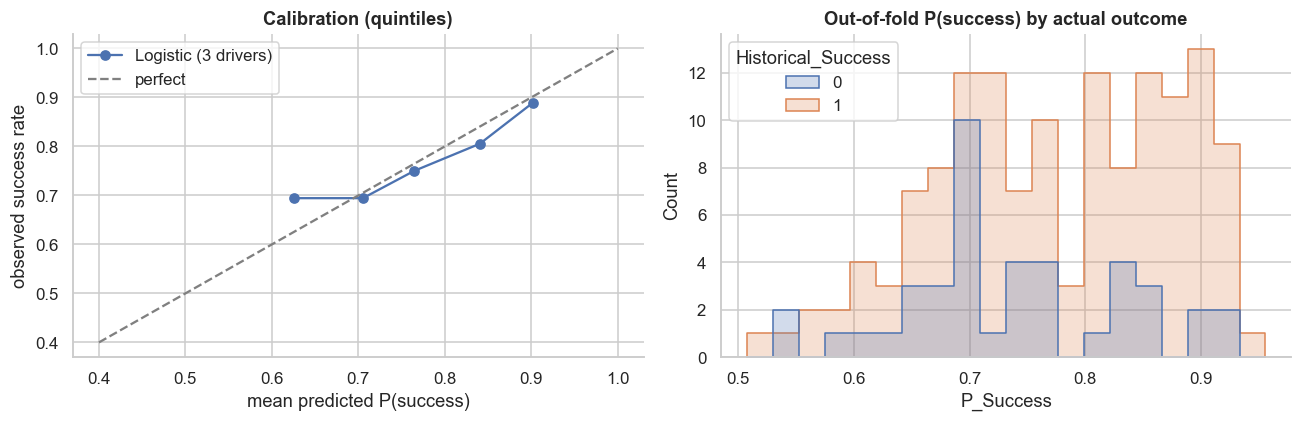

,n,predicted,observed
0,36,0.625,0.694
1,36,0.705,0.694
2,36,0.764,0.750
3,36,0.841,0.806
4,36,0.902,0.889


In [11]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
data['P_Success'] = cross_val_predict(models[chosen], X, y, cv=cv5, method='predict_proba')[:, 1]
print('Out-of-fold metrics for the chosen model:')
print(binary_report(y, data.P_Success, chosen).round(4))

cal = calibration_table(y, data.P_Success, bins=5)    # quintiles (36 per bin) because the data are small
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(cal.predicted, cal.observed, 'o-', label=chosen); ax[0].plot([0.4, 1], [0.4, 1], '--', c='grey', label='perfect')
ax[0].set_xlabel('mean predicted P(success)'); ax[0].set_ylabel('observed success rate'); ax[0].legend(); ax[0].set_title('Calibration (quintiles)')
sns.histplot(data=data, x='P_Success', hue='Historical_Success', bins=20, ax=ax[1], element='step')
ax[1].set_title('Out-of-fold P(success) by actual outcome')
plt.tight_layout(); savefig('init_model'); plt.show()
cal.round(3)

## 5. Explainability: what makes an initiative more likely to succeed? (SHAP)
SHAP splits each prediction into contributions from each feature. A positive SHAP value pushes the probability of
success **up**. The bar chart ranks features by their average absolute impact; the beeswarm shows the direction
(red = high feature value).

We fit the chosen model on all 180 initiatives (the deployable model) and explain it on the same data.
For logistic regression we also show the coefficients, which are the simplest explanation of all.

Background dataset has 180 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=180 when initializing the masker.


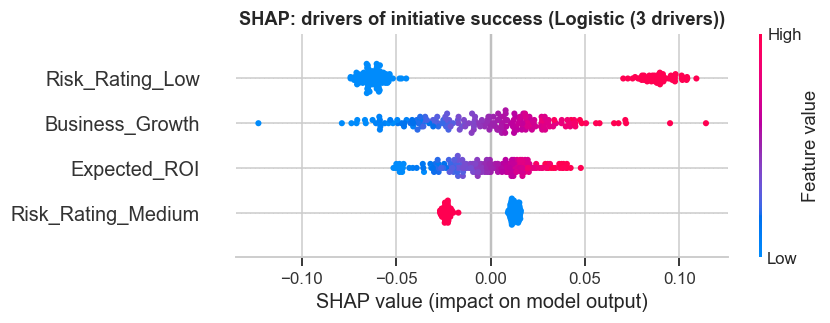

,mean |SHAP|,direction (+ raises success),logit coefficient
Risk_Rating_Low,0.0719,1.0,0.9837
Business_Growth,0.0286,1.0,0.2183
Expected_ROI,0.0187,1.0,0.1377
Risk_Rating_Medium,0.0171,-1.0,-0.2089


In [12]:
final = models[chosen].fit(X, y)
Xt = pd.DataFrame(final.named_steps['pre'].transform(X), columns=final.named_steps['pre'].get_feature_names_out())
Xt.columns = [c.split('__', 1)[1] for c in Xt.columns]    # drop the 'num__' / 'cat__' prefixes for readable plots
f_model = final.named_steps['m']

import shap
# Model-agnostic SHAP on the probability of success (works for any of the three models)
expl = shap_importance(lambda a: f_model.predict_proba(a)[:, 1], Xt, Xt)
fig = plt.figure(figsize=(8, 6)); shap.plots.beeswarm(expl, max_display=12, show=False)
plt.title(f'SHAP: drivers of initiative success ({chosen})'); plt.tight_layout(); savefig('init_shap'); plt.show()

shap_rank = pd.Series(np.abs(expl.values).mean(0), index=Xt.columns).sort_values(ascending=False)
direction = pd.Series([np.corrcoef(Xt[c], expl.values[:, i])[0, 1] for i, c in enumerate(Xt.columns)], index=Xt.columns)
drivers = pd.DataFrame({'mean |SHAP|': shap_rank, 'direction (+ raises success)': np.sign(direction[shap_rank.index])}).head(10)
if chosen.startswith('Logistic'):
    # For a logistic model the coefficient is the change in log-odds of success for +1 std (or for the category vs base)
    drivers['logit coefficient'] = pd.Series(f_model.coef_[0], index=Xt.columns)[drivers.index]
drivers.round(4)

**Plain-English drivers (for the Board).**
1. **Risk rating is the strongest signal.** A *Low* risk rating raises the odds of success the most (largest SHAP and
   coefficient). Medium-rated initiatives do no better than High-rated ones.
2. **Business growth** in the target segment raises the chance of success.
3. **Expected ROI** raises it too, but only mildly: a high promised ROI is not a guarantee.

Investment size, macro variables (GDP, interest rate) and competition add nothing reliable once these are known.
The ML message is therefore: *trust the risk rating, favour growing segments, and don't be dazzled by ROI alone*.

## 6. Financial layer (Task 3): NPV and expected NPV
**Cash flows.** For each initiative, the net cash flow in year *t* is `Revenue_Year_t − Operating_Cost`
(operating cost treated as an annual cost). The investment is paid up front (year 0).

**Horizon.** The file gives three years of revenue. Most bank initiatives (platforms, products) earn for longer
than three years, so the **base case assumes a 5-year life**: years 4 and 5 repeat the year-3 net cash flow, with no
growth and no salvage value. We also show the strict 3-year view and a 7-year view as a sensitivity.

$$NPV = -I_0 + \sum_{t=1}^{T} \frac{CF_t}{(1+r)^t}, \quad r = 12\%$$

**Expected NPV.** The brief's formula is $E[NPV] = P(success) \times NPV$, which implicitly assumes a failed
initiative is worth zero. That is optimistic: a failed project usually loses part of its investment. So we
compute two versions:
- **Brief version:** $E[NPV] = P \times NPV$.
- **Risk-adjusted version (used for decisions):** $E[NPV] = P \times NPV - (1-P) \times L \times I_0$, where
  $L$ is the share of the investment lost on failure. We assume $L$ = 30% for Low, 50% for Medium and 70% for High
  risk rating (riskier projects have less salvage value).

**Profitability index (PI)** = risk-adjusted E[NPV] ÷ investment. This is the value created **per rupee**, which is
what matters when capital is limited (₹1,000 crore across the whole group).

In [13]:
LOSS_ON_FAILURE = {'Low': 0.30, 'Medium': 0.50, 'High': 0.70}    # assumption, stated in the report

def npv(d, life=5, r=R):
    """NPV with yearly net cash flow = revenue - operating cost; years after 3 repeat the year-3 cash flow."""
    cf = [d[f'Revenue_Year{t}'] - d.Operating_Cost for t in (1, 2, 3)]
    cf += [cf[-1]] * (life - 3)                      # flat extension beyond year 3 (no growth, no salvage)
    return -d.Initial_Investment + sum(c / (1 + r) ** (t + 1) for t, c in enumerate(cf))

for life in (3, 5, 7):
    data[f'NPV_{life}y'] = npv(data, life)
data['NPV'] = data['NPV_5y']                         # base case
data['Loss_Rate'] = data.Risk_Rating.map(LOSS_ON_FAILURE)
data['ENPV_brief'] = data.P_Success * data.NPV
data['ENPV'] = data.P_Success * data.NPV - (1 - data.P_Success) * data.Loss_Rate * data.Initial_Investment
data['PI'] = data.ENPV / data.Initial_Investment

summary = pd.DataFrame({
    'share NPV > 0': [(data[f'NPV_{l}y'] > 0).mean() for l in (3, 5, 7)],
    'total NPV (₹ cr)': [data[f'NPV_{l}y'].sum() for l in (3, 5, 7)],
}, index=['3-year life', '5-year life (base)', '7-year life'])
print(summary.round(3))
print('\nBase case: initiatives with positive risk-adjusted E[NPV]:', int((data.ENPV > 0).sum()), 'of', len(data))
data[['Initiative_ID', 'Business_Unit', 'Initial_Investment', 'NPV', 'P_Success', 'ENPV_brief', 'ENPV', 'PI']].describe().T.round(2)

                    share NPV > 0  total NPV (₹ cr)
3-year life                 0.028        -14794.811
5-year life (base)          0.333         -5284.930
7-year life                 0.600          2296.290

Base case: initiatives with positive risk-adjusted E[NPV]: 39 of 180


,count,mean,std,min,25%,50%,75%,max
Initiative_ID,180.0,1090.50,52.11,1001.00,1045.75,1090.50,1135.25,1180.00
Initial_Investment,180.0,157.47,79.39,31.49,89.31,155.32,226.87,296.46
NPV,180.0,-29.36,74.09,-279.93,-69.14,-22.06,9.35,189.52
P_Success,180.0,0.77,0.10,0.51,0.70,0.76,0.86,0.96
ENPV_brief,180.0,-20.13,55.17,-177.61,-47.06,-16.57,6.75,162.68
ENPV,180.0,-39.03,61.19,-248.03,-75.78,-29.85,-4.28,157.25
PI,180.0,-0.25,0.33,-0.95,-0.49,-0.25,-0.06,0.71


**Why the horizon matters.** Over a strict 3-year life, three years of net revenue rarely pay back the investment,
so most projects show negative NPV. With 5 years, a meaningful share become positive. The decision rule below uses the
5-year base case, and section 8 tests what changes under 3 and 7 years.

## 7. Decision rule: Fund / Review / Reject
The brief's definitions:
- **Fund:** high expected value **and** acceptable risk.
- **Review:** potentially attractive but significant uncertainty.
- **Reject:** low expected value or excessive risk.

Our concrete rule (every threshold is an assumption we can defend and test):
1. **Reject** if risk-adjusted E[NPV] ≤ 0 (destroys value on average), or if P(success) < 0.60 (too uncertain to
   commit capital at all, whatever the upside).
2. **Fund** if PI ≥ 0.10 (at least 10 paise of expected value per rupee, a cushion for model and forecast error),
   P(success) ≥ 0.75 (close to or above the 77% base rate) **and** the risk rating is not High.
3. **Review** everything else: positive value but either thin, uncertain, or high-risk.

Finally, the Fund list is ranked by PI and funded within the ₹1,000 crore budget. Notebook 10 decides how much of
the group budget actually goes to initiatives, so here we only report the capital each group would need.

In [14]:
FUND_PI, FUND_P, REJECT_P = 0.10, 0.75, 0.60

def decide(r):
    if r.ENPV <= 0 or r.P_Success < REJECT_P:
        return 'Reject'
    if r.PI >= FUND_PI and r.P_Success >= FUND_P and r.Risk_Rating != 'High':
        return 'Fund'
    return 'Review'

data['Decision'] = data.apply(decide, axis=1)

# Budget check (greedy knapsack): go down the Fund list in order of PI (value per rupee).
# Take a project if it still fits in the remaining budget; if it does not fit, skip it and try the next,
# smaller one. This fills the budget with the highest value-per-rupee projects.
fund = data[data.Decision == 'Fund'].sort_values('PI', ascending=False).copy()
remaining, keep = BUDGET, []
for inv in fund.Initial_Investment:
    fits = inv <= remaining
    keep.append(fits)
    remaining -= inv if fits else 0
fund['Within_Budget'] = keep
fund['Cum_Investment'] = fund.Initial_Investment.cumsum()      # used only for the chart

dec = data.groupby('Decision').agg(Initiatives=('Initiative_ID', 'size'), Investment_cr=('Initial_Investment', 'sum'),
                                   ENPV_cr=('ENPV', 'sum'), Mean_P=('P_Success', 'mean'),
                                   Realised_success=('Historical_Success', 'mean')).reindex(['Fund', 'Review', 'Reject'])
print('Fund list: ', len(fund), 'initiatives, total investment ₹', round(fund.Initial_Investment.sum(), 1), 'cr;',
      int(fund.Within_Budget.sum()), 'fit inside the ₹1,000 cr budget (₹', round(BUDGET - remaining, 1), 'cr used)')
dec.round(3)

Fund list:  21 initiatives, total investment ₹ 3003.5 cr; 8 fit inside the ₹1,000 cr budget (₹ 970.9 cr used)


,Initiatives,Investment_cr,ENPV_cr,Mean_P,Realised_success
Decision,,,,,
Fund,21,3003.54,964.841,0.865,0.857
Review,18,2941.11,426.759,0.770,0.722
Reject,141,22400.09,-8417.871,0.753,0.759


**Backtest of the rule.** The `Realised_success` column is the historical success rate inside each decision group.
The model probabilities are out-of-fold, so this is an honest check: if the rule works, the Fund group should
have a clearly higher realised success rate than the Reject group.

In [15]:
# Where the money would go: Fund list by business unit, and how that maps to the Board's allocation categories.
BU_TO_LINE = {'Corporate Banking': 'Corporate lending', 'SME Lending': 'Retail lending', 'Digital Banking': 'Digital banking',
              'Payments': 'Digital banking', 'Wealth': 'Wealth management', 'Risk Analytics': 'Derivatives hedging'}
funded = fund[fund.Within_Budget]
by_bu = (funded.groupby('Business_Unit')
               .agg(Initiatives=('Initiative_ID', 'size'), Investment_cr=('Initial_Investment', 'sum'), ENPV_cr=('ENPV', 'sum'))
               .assign(PI=lambda t: t.ENPV_cr / t.Investment_cr, Allocation_line=lambda t: t.index.map(BU_TO_LINE))
               .sort_values('Investment_cr', ascending=False))
print('Funded portfolio: ₹', round(funded.Initial_Investment.sum(), 1), 'cr invested, risk-adjusted E[NPV] ₹',
      round(funded.ENPV.sum(), 1), 'cr, PI', round(funded.ENPV.sum() / funded.Initial_Investment.sum(), 3))
by_bu.round(3)

Funded portfolio: ₹ 970.9 cr invested, risk-adjusted E[NPV] ₹ 496.6 cr, PI 0.511


,Initiatives,Investment_cr,ENPV_cr,PI,Allocation_line
Business_Unit,,,,,
Wealth,2,414.89,263.104,0.634,Wealth management
Payments,3,342.27,135.828,0.397,Digital banking
Corporate Banking,1,103.26,59.188,0.573,Corporate lending
Digital Banking,1,62.95,24.555,0.390,Digital banking
Risk Analytics,1,47.56,13.891,0.292,Derivatives hedging


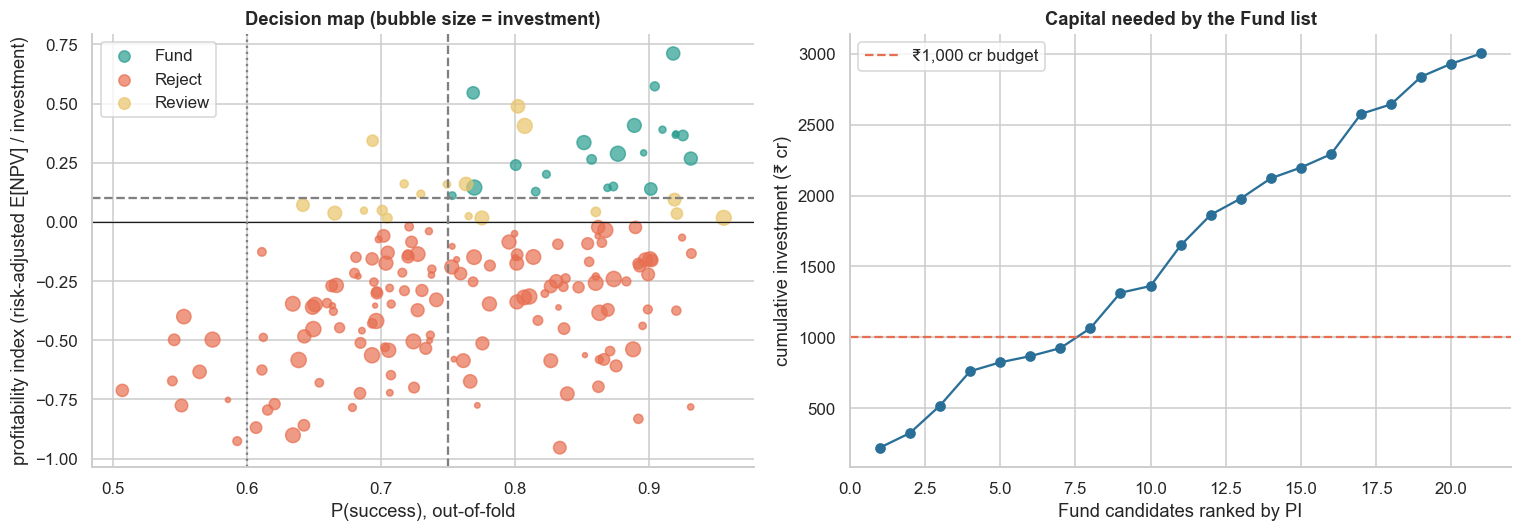

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
colors = {'Fund': '#2a9d8f', 'Review': '#e9c46a', 'Reject': '#e76f51'}
for k, g in data.groupby('Decision'):
    ax[0].scatter(g.P_Success, g.PI, s=g.Initial_Investment / 3, alpha=.7, label=k, c=colors[k])
ax[0].axhline(FUND_PI, ls='--', c='grey'); ax[0].axhline(0, c='k', lw=.8)
ax[0].axvline(FUND_P, ls='--', c='grey'); ax[0].axvline(REJECT_P, ls=':', c='grey')
ax[0].set_xlabel('P(success), out-of-fold'); ax[0].set_ylabel('profitability index (risk-adjusted E[NPV] / investment)')
ax[0].set_title('Decision map (bubble size = investment)'); ax[0].legend()
ax[1].plot(range(1, len(fund) + 1), fund.Cum_Investment.values, 'o-', c='#2a6f97')
ax[1].axhline(BUDGET, ls='--', c='#e76f51', label='₹1,000 cr budget'); ax[1].set_xlabel('Fund candidates ranked by PI')
ax[1].set_ylabel('cumulative investment (₹ cr)'); ax[1].set_title('Capital needed by the Fund list'); ax[1].legend()
plt.tight_layout(); savefig('init_decision'); plt.show()

## 8. Sensitivity and stress tests
The rule depends on assumptions. We change one at a time and count how the Fund list moves:
- project life (3 / 5 / 7 years),
- discount rate (10% / 12% / 14%),
- loss on failure (all 0%, as in the brief formula, vs base, vs 1.5× base),
- a **model-risk stress**: every P(success) cut by 10 percentage points.

In [17]:
def run_rule(life=5, r=R, loss_mult=1.0, p_shift=0.0):
    """Re-run NPV -> E[NPV] -> decision under different assumptions; return counts and capital in the Fund list."""
    d = data.copy()
    d['P_Success'] = (d.P_Success + p_shift).clip(0, 1)
    d['NPV'] = npv(d, life, r)
    loss = (d.Loss_Rate * loss_mult).clip(0, 1)
    d['ENPV'] = d.P_Success * d.NPV - (1 - d.P_Success) * loss * d.Initial_Investment
    d['PI'] = d.ENPV / d.Initial_Investment
    dd = d.apply(decide, axis=1)
    f = d[dd == 'Fund']
    return {'Fund': int((dd == 'Fund').sum()), 'Review': int((dd == 'Review').sum()), 'Reject': int((dd == 'Reject').sum()),
            'Fund investment (₹ cr)': f.Initial_Investment.sum(), 'Fund E[NPV] (₹ cr)': f.ENPV.sum(),
            'Overlap with base Fund list': len(set(f.Initiative_ID) & set(fund.Initiative_ID))}

scen = {'Base (5y, 12%, base loss)': run_rule(),
        'Life 3 years': run_rule(life=3), 'Life 7 years': run_rule(life=7),
        'Discount 10%': run_rule(r=0.10), 'Discount 14%': run_rule(r=0.14),
        'No loss on failure (brief formula)': run_rule(loss_mult=0.0), 'Loss on failure x1.5': run_rule(loss_mult=1.5),
        'Model stress: P(success) -10pp': run_rule(p_shift=-0.10)}
sens = pd.DataFrame(scen).T
sens.round(1)

,Fund,Review,Reject,Fund investment (₹ cr),Fund E[NPV] (₹ cr),Overlap with base Fund list
"Base (5y, 12%, base loss)",21.0,18.0,141.0,3003.5,964.8,21.0
Life 3 years,0.0,1.0,179.0,0.0,0.0,0.0
Life 7 years,42.0,40.0,98.0,6553.5,2926.6,21.0
Discount 10%,22.0,22.0,136.0,3204.3,1205.8,21.0
Discount 14%,15.0,17.0,148.0,2198.3,703.3,15.0
No loss on failure (brief formula),24.0,36.0,120.0,3504.0,1194.1,21.0
Loss on failure x1.5,19.0,13.0,148.0,2646.8,853.3,19.0
Model stress: P(success) -10pp,12.0,17.0,151.0,1785.5,553.6,12.0


## 9. Output table and hand-off to notebook 10

In [18]:
# Full decision table for every initiative (goes in the report appendix)
out_cols = ['Initiative_ID', 'Business_Unit', 'Risk_Rating', 'Initial_Investment', 'Expected_ROI', 'P_Success',
            'NPV_3y', 'NPV', 'NPV_7y', 'ENPV_brief', 'ENPV', 'PI', 'Decision', 'Historical_Success']
table = data[out_cols].sort_values(['Decision', 'PI'], ascending=[True, False])
table.to_csv(RES / 'initiatives_decisions.csv', index=False)
print('saved results/initiatives_decisions.csv')
table.head(15).round(3)

saved results/initiatives_decisions.csv


,Initiative_ID,Business_Unit,Risk_Rating,Initial_Investment,Expected_ROI,P_Success,NPV_3y,NPV,NPV_7y,ENPV_brief,ENPV,PI,Decision,Historical_Success
74,1075,Wealth,Low,220.85,18.85,0.918,25.250,177.194,298.323,162.676,157.248,0.712,Fund,0
61,1062,Corporate Banking,Low,103.26,15.42,0.904,-0.224,68.729,123.698,62.152,59.188,0.573,Fund,1
30,1031,Wealth,Medium,194.04,14.77,0.769,22.862,166.831,281.601,128.277,105.857,0.546,Fund,0
25,1026,Payments,Low,242.00,15.58,0.889,-25.863,120.103,236.465,106.780,98.727,0.408,Fund,1
40,1041,Digital Banking,Low,62.95,9.99,0.910,-7.614,28.847,57.914,26.253,24.555,0.390,Fund,0
148,1149,Payments,Low,43.90,21.37,0.920,-6.312,18.950,39.089,17.436,16.384,0.373,Fund,1
37,1038,Payments,Low,56.37,15.03,0.920,-9.070,23.999,50.361,22.074,20.718,0.368,Fund,1
106,1107,Wealth,Low,140.80,14.22,0.925,-23.649,59.041,124.962,54.630,51.474,0.366,Fund,1
73,1074,Corporate Banking,Medium,250.17,22.77,0.851,-20.143,120.385,232.413,102.506,83.929,0.335,Fund,1
32,1033,Risk Analytics,Low,47.56,14.05,0.896,-8.151,17.159,37.336,15.375,13.891,0.292,Fund,1


In [19]:
# Allocation rows: capital needed and expected return per Board allocation line.
# 'expected_annual_return' converts the 5-year E[NPV] into an annual excess return per rupee
# (PI spread evenly over the 5-year life). This is a rough, comparable number for notebook 10.
lines = {}
for line, g in funded.groupby(funded.Business_Unit.map(BU_TO_LINE)):
    lines[line] = {'initiatives': len(g), 'capital_cr': g.Initial_Investment.sum(), 'enpv_cr': g.ENPV.sum(),
                   'pi': g.ENPV.sum() / g.Initial_Investment.sum(),
                   'expected_annual_excess_return': g.ENPV.sum() / g.Initial_Investment.sum() / 5,
                   'mean_p_success': g.P_Success.mean()}

res = {'module': 'initiatives',
       'assumptions': {'discount_rate': R, 'life_years': 5, 'loss_on_failure': LOSS_ON_FAILURE,
                       'fund_pi_min': FUND_PI, 'fund_p_min': FUND_P, 'reject_p_below': REJECT_P,
                       'units': 'assumed INR crore'},
       'model': {'chosen': chosen, 'cv_roc_auc_mean': cvres.loc[chosen, 'ROC-AUC mean'],
                 'cv_roc_auc_std': cvres.loc[chosen, 'ROC-AUC std'],
                 'cv_table': cvres.round(4).to_dict(orient='index'),
                 'top_drivers': list(drivers.index[:5])},
       'decision_counts': data.Decision.value_counts().to_dict(),
       'realised_success_by_decision': dec.Realised_success.round(3).to_dict(),
       'funded_total_cr': funded.Initial_Investment.sum(), 'funded_enpv_cr': funded.ENPV.sum(),
       'review_total_cr': data.loc[data.Decision == 'Review', 'Initial_Investment'].sum(),
       'lines': lines,
       'sensitivity': sens.round(2).to_dict(orient='index')}
save_result('initiatives', res)

saved results/Module_01_Strategic_Initiatives/initiatives.json


## Reading the sensitivity table
- **Project life is the assumption that matters most.** Under a strict 3-year view, almost nothing pays back, so
  nothing is funded. Under 7 years the Fund list doubles. This should be stated as the key judgement in the report.
- **The core of the Fund list is stable.** Every scenario that makes the rule stricter (higher discount, larger loss,
  lower P) keeps a *subset* of the base Fund list, so the top-ranked projects are robust picks.
- **Model stress** (every P(success) 10 points lower) still leaves 12 projects in Fund. The decision does not hinge on
  the model being optimistic.

## Headline results (base case: 5-year life, 12% discount rate, risk-based loss on failure)
- **Model.** Logistic regression on 3 drivers (risk rating, business growth, expected ROI). CV ROC-AUC 0.63 ± 0.10
  (50 folds). Random forest and gradient boosting were worse (0.45 and 0.50). Success is only weakly predictable,
  so the NPV screen does most of the work and P(success) is a risk adjustment.
- **Drivers.** Low risk rating is the strongest success factor, then segment growth, then expected ROI.
- **NPV.** Only 3% of initiatives pay back within 3 years. With a 5-year life, 33% have positive NPV.
- **Decision.** Fund 21 (₹3,004 cr), Review 18 (₹2,941 cr), Reject 141. Historical success rate: Fund 86%,
  Review 72%, Reject 76%. The Reject group is driven by poor value, not by low success odds.
- **Within ₹1,000 cr** (ranked by value per rupee): 8 initiatives, ₹971 cr, risk-adjusted E[NPV] ₹497 cr
  (PI 0.51). By line: Wealth ₹415 cr, Digital banking/Payments ₹405 cr, Corporate ₹103 cr, Risk analytics ₹48 cr.
- **For notebook 10.** The initiatives alone could absorb the whole budget, so notebook 10 has to cap them against the
  other business lines. Use PI (value per rupee) to compare them with lending, equity and the other lines.

## Risks and limitations
- 180 rows and 42 failures: model estimates are noisy; the 3 drivers were chosen after looking at the data.
- Revenue columns are assumed to be ex-ante projections; if they are realised values the model would leak.
- NPV uses a flat extension beyond year 3, no tax, no salvage value, and a single 12% rate for every business unit.
- Loss-on-failure rates (30/50/70%) are assumptions; the sensitivity table shows their effect.
- Units are assumed ₹ crore; under lakh every rupee total shrinks 100× but the ranking is unchanged.